In [1]:
import copy
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
MAX_EPOCHS = 40
PATIENCE = 8
BATCH_SIZE = 128
HIDDEN_SIZE = 64
LEARNING_RATE = 0.001

DATA_DIR = Path('/content/UCI HAR Dataset')
ZIP_PATH = Path('/content/har.zip')
MODEL_PATH = Path('/content/har_bilstm_sensor_enhanced.pkl')
DATA_URL = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'

CHANNELS = [
    'body_acc_x', 'body_acc_y', 'body_acc_z',
    'body_gyro_x', 'body_gyro_y', 'body_gyro_z',
    'total_acc_x', 'total_acc_y', 'total_acc_z'
]
ACTIVITY_NAMES = [
    'WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS',
    'SITTING', 'STANDING', 'LAYING'
]

torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Device:', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')


PyTorch: 2.11.0+cpu
Device: CPU


In [2]:
if not DATA_DIR.exists():
    print('Downloading UCI HAR dataset (~58 MB) into Colab...')
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

    # Extract outer zip
    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extractall('/content')

    # The outer zip contains 'UCI HAR Dataset.zip'. We must extract this inner zip.
    inner_zip_path = Path('/content/UCI HAR Dataset.zip')
    if inner_zip_path.exists():
        print('Extracting inner dataset zip...')
        with zipfile.ZipFile(inner_zip_path) as archive:
            archive.extractall('/content')
        inner_zip_path.unlink(missing_ok=True)

    ZIP_PATH.unlink(missing_ok=True)
    print('Dataset extracted successfully.')
else:
    print('Dataset is already available.')

Extracting inner dataset zip...
Dataset extracted successfully.


In [3]:
import os

# Automatically locate the correct dataset directory, in case it is nested or named differently
possible_dirs = list(Path('/content').glob('**/UCI HAR Dataset'))
if possible_dirs:
    DATA_DIR = possible_dirs[0]
else:
    DATA_DIR = Path('/content/UCI HAR Dataset')

def load_split(split):
    signal_dir = DATA_DIR / split / 'Inertial Signals'
    signals = [
        np.loadtxt(signal_dir / f'{name}_{split}.txt', dtype=np.float32)
        for name in CHANNELS
    ]
    X = np.stack(signals, axis=-1)  # examples x time steps x sensor channels
    y = np.loadtxt(DATA_DIR / split / f'y_{split}.txt', dtype=np.int64) - 1
    return X, y

X_train, y_train = load_split('train')
X_test, y_test = load_split('test')
print('Training:', X_train.shape, y_train.shape)
print('Test:', X_test.shape, y_test.shape)

Training: (7352, 128, 9) (7352,)
Test: (2947, 128, 9) (2947,)


In [4]:
X_train_full = X_train.copy()
y_train_full = y_train.copy()
X_test_raw = X_test.copy()
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.15,
    random_state=SEED,
    stratify=y_train_full
)

# These statistics are used for model selection only.
mean = X_train.mean(axis=(0, 1), keepdims=True).astype(np.float32)
std = (X_train.std(axis=(0, 1), keepdims=True) + 1e-8).astype(np.float32)
X_train = ((X_train - mean) / std).astype(np.float32)
X_val = ((X_val - mean) / std).astype(np.float32)
X_test = ((X_test_raw - mean) / std).astype(np.float32)

def make_loader(X, y, batch_size, shuffle=False):
    dataset = TensorDataset(
        torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32)),
        torch.from_numpy(np.asarray(y, dtype=np.int64))
    )
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      pin_memory=(device.type == 'cuda'))

train_loader = make_loader(X_train, y_train, BATCH_SIZE, shuffle=True)
val_loader = make_loader(X_val, y_val, 256)
test_loader = make_loader(X_test, y_test, 256)

print('Model selection split - Train:', X_train.shape,
      '| Validation:', X_val.shape, '| Official test:', X_test.shape)


Model selection split - Train: (6249, 128, 9) | Validation: (1103, 128, 9) | Official test: (2947, 128, 9)


In [5]:
class HARBiLSTM(nn.Module):
    """Reference model matching the original single-layer BiLSTM."""
    def __init__(self, input_size=9, hidden_size=64, num_classes=6):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True, bidirectional=True)
        self.classifier = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        final_states = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.classifier(final_states)


class HARConvBiLSTM(nn.Module):
    """Temporal CNN + BiLSTM with attention-weighted time pooling."""
    def __init__(self, input_size=9, hidden_size=64, num_classes=6):
        super().__init__()
        self.temporal_cnn = nn.Sequential(
            nn.Conv1d(input_size, 64, kernel_size=7, padding=3, bias=False),
            nn.BatchNorm1d(64),
            nn.GELU(),
            nn.Conv1d(64, 64, kernel_size=5, padding=2, bias=False),
            nn.BatchNorm1d(64),
            nn.GELU(),
            nn.Dropout(0.20),
        )
        self.lstm = nn.LSTM(
            input_size=64,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.25,
        )
        self.attention = nn.Linear(hidden_size * 2, 1)
        self.dropout = nn.Dropout(0.35)
        self.classifier = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x):
        x = self.temporal_cnn(x.transpose(1, 2)).transpose(1, 2)
        sequence, _ = self.lstm(x)
        weights = torch.softmax(self.attention(sequence).squeeze(-1), dim=1)
        pooled = torch.sum(sequence * weights.unsqueeze(-1), dim=1)
        return self.classifier(self.dropout(pooled))

print('Both models accept:', len(CHANNELS), 'sensor channels')


Both models accept: 9 sensor channels


In [6]:
def evaluate_accuracy(model, loader):
    model.eval()
    correct = total = 0
    with torch.inference_mode():
        for xb, yb in loader:
            xb = xb.to(device, non_blocking=(device.type == 'cuda'))
            logits = model(xb)
            correct += (logits.argmax(dim=1).cpu() == yb).sum().item()
            total += len(yb)
    return correct / max(total, 1)


def train_candidate(model_class, name):
    model = model_class(
        input_size=len(CHANNELS),
        hidden_size=HIDDEN_SIZE,
        num_classes=len(ACTIVITY_NAMES)
    ).to(device)
    loss_fn = nn.CrossEntropyLoss(label_smoothing=0.02)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=0.5, patience=3, min_lr=1e-5
    )
    best_val = -1.0
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(MAX_EPOCHS):
        model.train()
        total_loss = 0.0
        for xb, yb in train_loader:
            xb = xb.to(device, non_blocking=(device.type == 'cuda'))
            yb = yb.to(device, non_blocking=(device.type == 'cuda'))
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()

        val_accuracy = evaluate_accuracy(model, val_loader)
        scheduler.step(val_accuracy)
        average_loss = total_loss / max(len(train_loader), 1)
        print(f'{name} | Epoch {epoch + 1}: loss={average_loss:.4f}, val_acc={val_accuracy * 100:.2f}%')

        if val_accuracy > best_val:
            best_val = val_accuracy
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                print(f'{name}: early stopping.')
                break

    return best_val, best_epoch


candidates = [
    ('Original BiLSTM', HARBiLSTM),
    ('Temporal CNN-BiLSTM', HARConvBiLSTM),
]
selection_results = []
for model_name, model_class in candidates:
    val_accuracy, best_epoch = train_candidate(model_class, model_name)
    selection_results.append((model_name, model_class, val_accuracy, best_epoch))

best_model_name, selected_class, best_val_accuracy, selected_epochs = max(
    selection_results, key=lambda item: item[2]
)
print(f'\nSelected by validation: {best_model_name}')
print(f'Best validation accuracy: {best_val_accuracy * 100:.2f}% at epoch {selected_epochs}')

# Refit the selected architecture using every official training example.
# The official test set remains untouched until the next section.
mean = X_train_full.mean(axis=(0, 1), keepdims=True).astype(np.float32)
std = (X_train_full.std(axis=(0, 1), keepdims=True) + 1e-8).astype(np.float32)
X_train_refit = ((X_train_full - mean) / std).astype(np.float32)
X_test = ((X_test_raw - mean) / std).astype(np.float32)
train_loader = make_loader(X_train_refit, y_train_full, BATCH_SIZE, shuffle=True)
test_loader = make_loader(X_test, y_test, 256)

model = selected_class(
    input_size=len(CHANNELS),
    hidden_size=HIDDEN_SIZE,
    num_classes=len(ACTIVITY_NAMES)
).to(device)
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.02)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=max(selected_epochs, 1), eta_min=1e-5
)
print(f'Retraining on all {len(X_train_refit)} official training examples for {selected_epochs} epochs...')
for epoch in range(selected_epochs):
    model.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        xb = xb.to(device, non_blocking=(device.type == 'cuda'))
        yb = yb.to(device, non_blocking=(device.type == 'cuda'))
        optimizer.zero_grad(set_to_none=True)
        loss = loss_fn(model(xb), yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()
    scheduler.step()
    print(f'Full-data refit epoch {epoch + 1}/{selected_epochs} - loss: {total_loss / max(len(train_loader), 1):.4f}')


Original BiLSTM | Epoch 1: loss=1.4795, val_acc=56.48%
Original BiLSTM | Epoch 2: loss=0.8650, val_acc=72.08%
Original BiLSTM | Epoch 3: loss=0.6309, val_acc=83.32%
Original BiLSTM | Epoch 4: loss=0.4625, val_acc=91.75%
Original BiLSTM | Epoch 5: loss=0.3545, val_acc=94.47%
Original BiLSTM | Epoch 6: loss=0.2934, val_acc=94.47%
Original BiLSTM | Epoch 7: loss=0.2870, val_acc=94.20%
Original BiLSTM | Epoch 8: loss=0.2611, val_acc=94.92%
Original BiLSTM | Epoch 9: loss=0.2545, val_acc=94.29%
Original BiLSTM | Epoch 10: loss=0.2491, val_acc=96.10%
Original BiLSTM | Epoch 11: loss=0.2353, val_acc=95.10%
Original BiLSTM | Epoch 12: loss=0.2380, val_acc=95.19%
Original BiLSTM | Epoch 13: loss=0.2279, val_acc=95.83%
Original BiLSTM | Epoch 14: loss=0.2285, val_acc=96.01%
Original BiLSTM | Epoch 15: loss=0.2222, val_acc=96.01%
Original BiLSTM | Epoch 16: loss=0.2161, val_acc=96.28%
Original BiLSTM | Epoch 17: loss=0.2155, val_acc=95.47%
Original BiLSTM | Epoch 18: loss=0.2135, val_acc=96.37%
O

Selected model: Temporal CNN-BiLSTM
Test accuracy: 93.18%
                    precision    recall  f1-score   support

           WALKING     1.0000    0.9940    0.9970       496
  WALKING_UPSTAIRS     0.9832    0.9936    0.9884       471
WALKING_DOWNSTAIRS     0.9929    0.9976    0.9952       420
           SITTING     0.7952    0.8147    0.8048       491
          STANDING     0.8314    0.8064    0.8187       532
            LAYING     1.0000    1.0000    1.0000       537

          accuracy                         0.9318      2947
         macro avg     0.9338    0.9344    0.9340      2947
      weighted avg     0.9317    0.9318    0.9317      2947



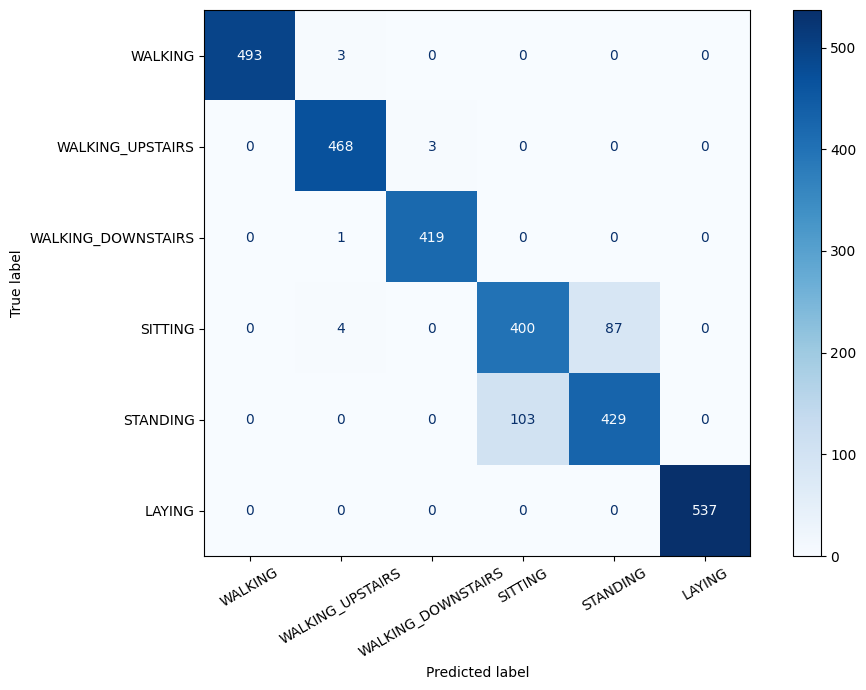

In [7]:
model.eval()
all_predictions = []
all_labels = []
with torch.inference_mode():
    for X_batch, y_batch in test_loader:
        logits = model(X_batch.to(device, non_blocking=(device.type == 'cuda')))
        all_predictions.extend(logits.argmax(dim=1).cpu().numpy())
        all_labels.extend(y_batch.numpy())

accuracy = float(np.mean(np.asarray(all_predictions) == np.asarray(all_labels)))
print(f'Selected model: {best_model_name}')
print(f'Test accuracy: {accuracy * 100:.2f}%')
print(classification_report(
    all_labels, all_predictions,
    target_names=ACTIVITY_NAMES,
    zero_division=0,
    digits=4
))

fig, ax = plt.subplots(figsize=(10, 7))
ConfusionMatrixDisplay.from_predictions(
    all_labels, all_predictions,
    display_labels=ACTIVITY_NAMES,
    xticks_rotation=30,
    cmap='Blues',
    ax=ax
)
fig.tight_layout()
plt.show()


In [8]:
checkpoint = {
    'model_name': best_model_name,
    'model_state_dict': {k: v.detach().cpu() for k, v in model.state_dict().items()},
    'input_size': len(CHANNELS),
    'hidden_size': HIDDEN_SIZE,
    'num_classes': len(ACTIVITY_NAMES),
    'mean': torch.from_numpy(mean.copy()),
    'std': torch.from_numpy(std.copy()),
    'activity_names': ACTIVITY_NAMES,
    'channels': CHANNELS,
    'best_validation_accuracy': float(best_val_accuracy),
    'refit_epochs': int(selected_epochs),
    'test_accuracy': float(accuracy),
}
torch.save(checkpoint, MODEL_PATH)
print('Saved:', MODEL_PATH)
try:
    from google.colab import files
    files.download(str(MODEL_PATH))
except ImportError:
    print('Outside Colab: download the checkpoint from the path above.')


Saved: /content/har_bilstm_sensor_enhanced.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>